In [46]:
import torch
import torchaudio

In [47]:
waveform, sr = torchaudio.load("IISc_SYSPINProject_te_f_AGRI_00014.wav")

In [40]:
sr

48000

In [50]:
num_samples = int(sr * 1.0)
if waveform.shape[1] < num_samples:
    waveform = torch.nn.functional.pad(waveform, (0, num_samples - waveform.shape[1]))
else:
    waveform = waveform[:, :num_samples]

mel_spec = torchaudio.transforms.MelSpectrogram(
    sample_rate=sr,
    n_fft=1024,
    hop_length=160,   # ~10 ms
    win_length=400,   # ~25 ms
    n_mels=80
)(waveform)

log_mel_spec = torchaudio.transforms.AmplitudeToDB()(mel_spec)

print(log_mel_spec.shape)

torch.Size([1, 80, 301])


In [42]:
log_mel_spec.shape

torch.Size([1, 80, 301])

In [43]:
log_mel_spec[0]

tensor([[-13.3700, -17.0294, -10.3031,  ..., -10.8857,  -5.0424,  -4.2360],
        [-12.8551, -16.0599, -10.1491,  ...,  -5.8799,  -1.2682,  -4.7717],
        [-11.7686, -13.6567, -10.6667,  ...,   0.3876,   4.4143, -19.7952],
        ...,
        [-50.7519, -53.2237, -64.5223,  ..., -46.7194, -47.3153, -40.6395],
        [-61.0301, -51.3802, -52.9341,  ..., -42.5162, -39.7007, -39.5753],
        [-63.8010, -60.1622, -50.9625,  ..., -49.0050, -44.5040, -37.0850]])

Spectrogram shape: (80, 301) (mel_bins x frames), duration ~1.003s


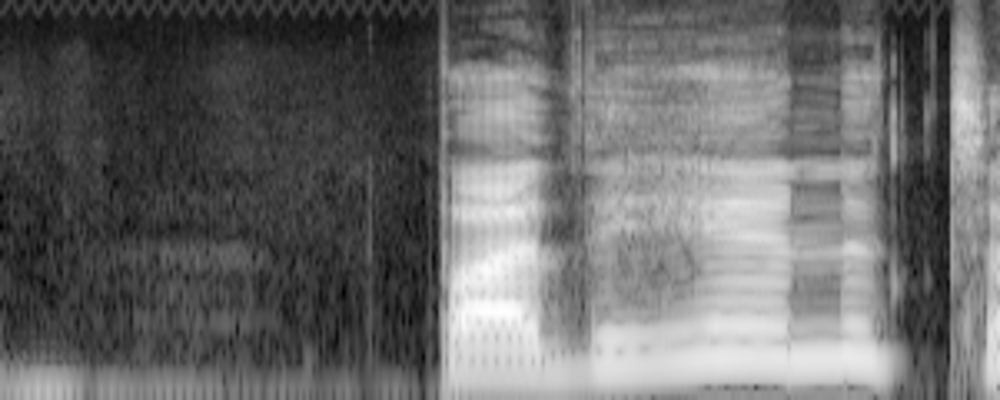

In [54]:
import numpy as np
from IPython.display import display
from PIL import Image

# Matplotlib-free spectrogram rendering (stable in this environment)
sr = int(sr)
hop = 160
data = log_mel_spec[0].detach().cpu().numpy().astype(np.float32)
data = np.nan_to_num(data, nan=-80.0, posinf=0.0, neginf=-80.0)

duration_sec = data.shape[1] * hop / sr
print(f'Spectrogram shape: {data.shape} (mel_bins x frames), duration ~{duration_sec:.3f}s')

# Normalize to [0, 255] and flip vertically for low->high mel bottom-to-top
dmin, dmax = float(data.min()), float(data.max())
norm = (data - dmin) / (dmax - dmin + 1e-8)
img8 = (255.0 * np.flipud(norm)).astype(np.uint8)

# Enlarge for readability
img = Image.fromarray(img8).resize((1000, 400))
display(img)